# Estimator functions

## Notebook setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (5, 2)},
)

# Simplified int and float __repr__
np.set_printoptions(legacy="1.25")

<Figure size 640x480 with 0 Axes>

## Estimators

### Using `mean`

Compute the arithmetic mean of the observations in a sample by dividing their sum by the sample size.

In [2]:
from ministats import mean
from scipy.stats import norm

In [3]:
np.random.seed(42)
rvX = norm(loc=120, scale=13)
xs = rvX.rvs(size=30)
mean(xs)

117.55409035393652

### Using `var`

Compute the sample variance using the sum of squared deviations from the sample mean divided by $n-1$. This is the unbiased variance estimator and requires at least two observations.

In [4]:
from ministats import var
from scipy.stats import norm

In [5]:
np.random.seed(42)
rvX = norm(loc=120, scale=13)
xs = rvX.rvs(size=30)
var(xs)

136.8919552227952

### Using `std`

Compute the sample standard deviation as the square root of the sample variance, using the $n-1$ denominator. The sample is identical to the ones used for `mean` and `var`.

In [6]:
from ministats import std
from scipy.stats import norm

In [7]:
np.random.seed(42)
rvX = norm(loc=120, scale=13)
xs = rvX.rvs(size=30)
std(xs)

11.700083556231348

### Using `dmeans`

Estimate the difference between two population means by subtracting the second sample mean from the first: $\overline{x}-\overline{y}$. The example samples from normal populations with means 120 and 100 and standard deviations 13 and 17, respectively.

In [8]:
from ministats import dmeans
from scipy.stats import norm

In [9]:
# Two populations X ~ N(120, 13) and Y ~ N(100, 17).
muX, muY = 120, 100
sigmaX, sigmaY = 13, 17
rvX = norm(muX, sigmaX)
rvY = norm(muY, sigmaY)

np.random.seed(42)
xs = rvX.rvs(size=30)
np.random.seed(43)
ys = rvY.rvs(size=40)
dmeans(xs, ys)

15.528596609707066

### Using `median`

Sort the observations and return the middle value when the sample size is odd, or the average of the two middle values when the sample size is even.

In [10]:
from ministats import median
from scipy.stats import norm

In [11]:
np.random.seed(42)
rvX = norm(loc=120, scale=13)
xs = rvX.rvs(size=30)
median(xs)

116.95611284412864

### Using `quantile`

Compute a sample quantile at probability `q` by linearly interpolating between adjacent sorted observations at the fractional index $q(n-1)$. This implementation requires at least two observations and `0 <= q < 1`; it does not handle `q=1`.

In [12]:
from ministats import quantile
from scipy.stats import norm

In [13]:
np.random.seed(42)
rvX = norm(loc=120, scale=13)
xs = rvX.rvs(size=30)
quantile(xs, q=0.25)

112.3163383032585

### Using `gen_sampling_dist`

Simulate `N` independent samples of size `n` from the random variable `rv`, apply `estfunc` to each sample, and return the resulting list of `N` estimates. The example plots a simulation approximation to the sampling distribution of the mean.

In [14]:
from ministats import gen_sampling_dist, mean
from scipy.stats import norm

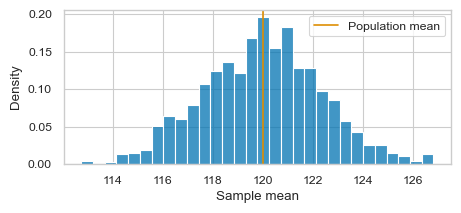

In [15]:
np.random.seed(44)
rvX = norm(loc=120, scale=13)
xbars = gen_sampling_dist(rvX, estfunc=mean, n=30, N=1000)

ax = sns.histplot(xbars, bins=30, stat="density")
ax.axvline(rvX.mean(), color="C1", label="Population mean")
ax.set(xlabel="Sample mean", ylabel="Density")
ax.legend()
plt.show()